# 01 · Başlangıç: ChestMNIST verisini yükleme ve tanıma

**Proje:** Göğüs röntgeninden pnömoni tahmini · SVY 5430 · BVYZ-XX

Bu defter Teslim 1 kapsamındadır ve yalnızca **veriyi tanımayı** amaçlar; model sonraki teslimlerde kurulacaktır.

1. ChestMNIST'i 128 × 128 çözünürlükte indirme ve yükleme
2. Bölme boyutları, veri tipi ve piksel aralığı kontrolü
3. 14 etiketin dağılımı ve hedef değişken (pnömoni)
4. Örnek görüntüler
5. Bulgular

## 1. Kurulum ve veriyi indirme

In [6]:
!pip install -q medmnist==3.0.2

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from medmnist import ChestMNIST, INFO

SEED = 42
rng = np.random.default_rng(SEED)
PNEUMONIA_IDX = 6  # ChestMNIST'te 6. sütun pnömoni etiketidir

In [10]:
# Veriyi Drive'a indiriyoruz; böylece her oturumda yeniden indirmek gerekmez
from google.colab import drive
drive.mount('/content/drive')

target_dir = '/content/drive/MyDrive/Machine Learning/Datasets/MedMNIST/'
os.makedirs(target_dir, exist_ok=True)

# Dosya zaten varsa yeniden indirilmez (~1,4 GB, ilk indirme uzun sürebilir)
print(f"ChestMNIST (128x128) veri seti: {target_dir}")
ChestMNIST(split='train', download=True, size=128, root=target_dir)
print("Veri hazır!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ChestMNIST (128x128) veri seti: /content/drive/MyDrive/Machine Learning/Datasets/MedMNIST/
Veri hazır!


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 2. Veriyi yükleme ve temel kontroller

In [11]:
file_path = os.path.join(target_dir, "chestmnist_128.npz")
with np.load(file_path) as npz:
    data = {anahtar: npz[anahtar] for anahtar in npz.files}  # tek seferde belleğe al

print("Arşivdeki bölümler:", list(data.keys()))
for anahtar, dizi in data.items():
    print(f"Bölüm: {anahtar:<12} | Boyut: {str(dizi.shape):<18} | Tip: {dizi.dtype} | "
          f"Değer aralığı: [{dizi.min()}, {dizi.max()}]")

Arşivdeki bölümler: ['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels']
Bölüm: train_images | Boyut: (78468, 128, 128)  | Tip: uint8 | Değer aralığı: [0, 255]
Bölüm: train_labels | Boyut: (78468, 14)        | Tip: uint8 | Değer aralığı: [0, 1]
Bölüm: val_images   | Boyut: (11219, 128, 128)  | Tip: uint8 | Değer aralığı: [0, 255]
Bölüm: val_labels   | Boyut: (11219, 14)        | Tip: uint8 | Değer aralığı: [0, 1]
Bölüm: test_images  | Boyut: (22433, 128, 128)  | Tip: uint8 | Değer aralığı: [0, 255]
Bölüm: test_labels  | Boyut: (22433, 14)        | Tip: uint8 | Değer aralığı: [0, 1]


In [12]:
# Bölme boyutları ve oranları
bolmeler = ["train", "val", "test"]
n = {s: len(data[f"{s}_labels"]) for s in bolmeler}
toplam = sum(n.values())
for s in bolmeler:
    print(f"{s:<5}: {n[s]:>6} görüntü  (%{100 * n[s] / toplam:.1f})")
print(f"Toplam: {toplam}")

train:  78468 görüntü  (%70.0)
val  :  11219 görüntü  (%10.0)
test :  22433 görüntü  (%20.0)
Toplam: 112120


## 3. Veri setinin üst bilgisi ve etiketler

ChestMNIST **çok etiketli** (multi-label) bir veri setidir: her görüntü için 14 bulgunun her biri 0 veya 1'dir ve bir görüntüde birden fazla bulgu olabilir.

In [13]:
info = INFO["chestmnist"]
LABELS = [info["label"][str(i)] for i in range(len(info["label"]))]

print("Görev :", info["task"])
print("Lisans:", info["license"])
print("\nEtiketler:")
for i, ad in enumerate(LABELS):
    print(f"  {i:2d}  {ad}{'   <-- hedef' if i == PNEUMONIA_IDX else ''}")

Görev : multi-label, binary-class
Lisans: CC BY 4.0

Etiketler:
   0  atelectasis
   1  cardiomegaly
   2  effusion
   3  infiltration
   4  mass
   5  nodule
   6  pneumonia   <-- hedef
   7  pneumothorax
   8  consolidation
   9  edema
  10  emphysema
  11  fibrosis
  12  pleural
  13  hernia


## 4. Etiket dağılımı

In [14]:
yayginlik = pd.DataFrame(
    {f"{s} (%)": 100 * data[f"{s}_labels"].mean(axis=0) for s in bolmeler},
    index=LABELS).round(2)
yayginlik.sort_values("train (%)", ascending=False)

,train (%),val (%),test (%)
infiltration,17.73,17.99,17.55
effusion,11.80,11.52,12.28
atelectasis,10.19,9.97,10.79
nodule,5.58,5.46,5.95
mass,5.08,5.57,5.05
pneumothorax,4.72,4.49,4.85
consolidation,4.16,3.98,4.27
pleural,2.90,3.32,3.27
cardiomegaly,2.49,2.14,2.59
emphysema,2.29,1.85,2.27


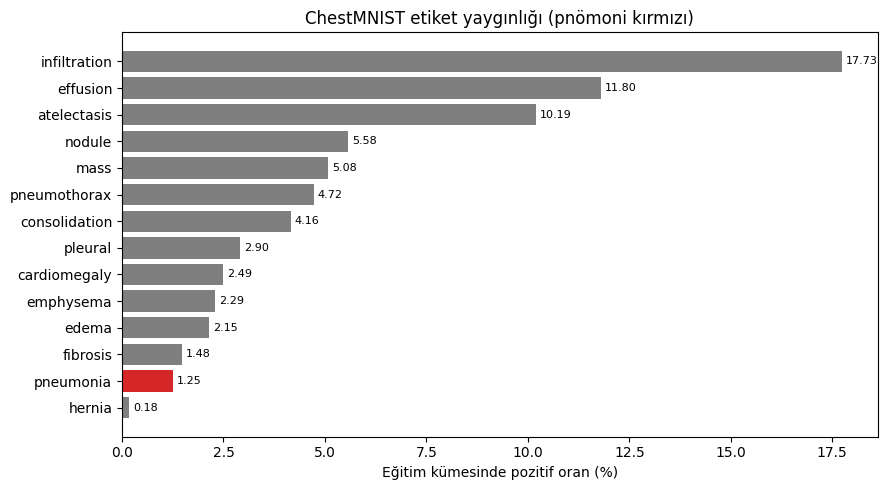

In [15]:
p = yayginlik["train (%)"].sort_values()
renkler = ["tab:red" if ad == "pneumonia" else "tab:gray" for ad in p.index]

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(p.index, p.values, color=renkler)
for i, v in enumerate(p.values):
    ax.text(v + 0.1, i, f"{v:.2f}", va="center", fontsize=8)
ax.set_xlabel("Eğitim kümesinde pozitif oran (%)")
ax.set_title("ChestMNIST etiket yaygınlığı (pnömoni kırmızı)")
plt.tight_layout()
plt.show()

## 5. Hedef değişken: pnömoni

Projede 14 etiketten yalnızca pnömoni sütunu alınarak problem **ikili sınıflandırmaya** (pnömoni var / yok) indirgenecektir.

In [16]:
y = {s: data[f"{s}_labels"][:, PNEUMONIA_IDX].astype(int) for s in bolmeler}

satirlar = []
for s in bolmeler:
    pos = int(y[s].sum())
    satirlar.append({"bölme": s, "n": n[s], "pnömoni (+)": pos, "pnömoni (−)": n[s] - pos,
                     "pozitif oran (%)": round(100 * pos / n[s], 2),
                     "negatif / pozitif": round((n[s] - pos) / pos, 1)})
pd.DataFrame(satirlar).set_index("bölme")

,n,pnömoni (+),pnömoni (−),pozitif oran (%),negatif / pozitif
bölme,,,,,
train,78468,978,77490,1.25,79.2
val,11219,133,11086,1.19,83.4
test,22433,242,22191,1.08,91.7


In [17]:
# Görüntü başına bulgu sayısı
train_labels = data["train_labels"]
bulgu_sayisi = train_labels.sum(axis=1)
pos_mask = y["train"] == 1

print(f"Bulgu yok (tüm etiketler 0) : %{100 * (bulgu_sayisi == 0).mean():.1f}")
print(f"Tek bulgu                   : %{100 * (bulgu_sayisi == 1).mean():.1f}")
print(f"İki veya daha fazla bulgu   : %{100 * (bulgu_sayisi >= 2).mean():.1f}")
print(f"\nPnömonili görüntülerde yalnızca pnömoni etiketi olanlar: "
      f"%{100 * (bulgu_sayisi[pos_mask] == 1).mean():.1f}")

Bulgu yok (tüm etiketler 0) : %54.0
Tek bulgu                   : %27.5
İki veya daha fazla bulgu   : %18.4

Pnömonili görüntülerde yalnızca pnömoni etiketi olanlar: %21.5


In [18]:
# Pnömoniyle birlikte görülen bulgular: pnömonili görüntülerdeki oran ve genel oran
eslik = pd.DataFrame({
    "pnömoni (+) içinde (%)": 100 * train_labels[pos_mask].mean(axis=0),
    "tüm eğitim kümesinde (%)": 100 * train_labels.mean(axis=0),
}, index=LABELS).drop("pneumonia").round(1)
eslik.sort_values("pnömoni (+) içinde (%)", ascending=False)

,pnömoni (+) içinde (%),tüm eğitim kümesinde (%)
infiltration,42.3,17.7
edema,25.2,2.2
effusion,19.9,11.8
atelectasis,19.2,10.2
consolidation,8.8,4.2
mass,4.3,5.1
nodule,4.2,5.6
pleural,3.5,2.9
pneumothorax,2.4,4.7
cardiomegaly,2.1,2.5


## 6. Örnek görüntüler

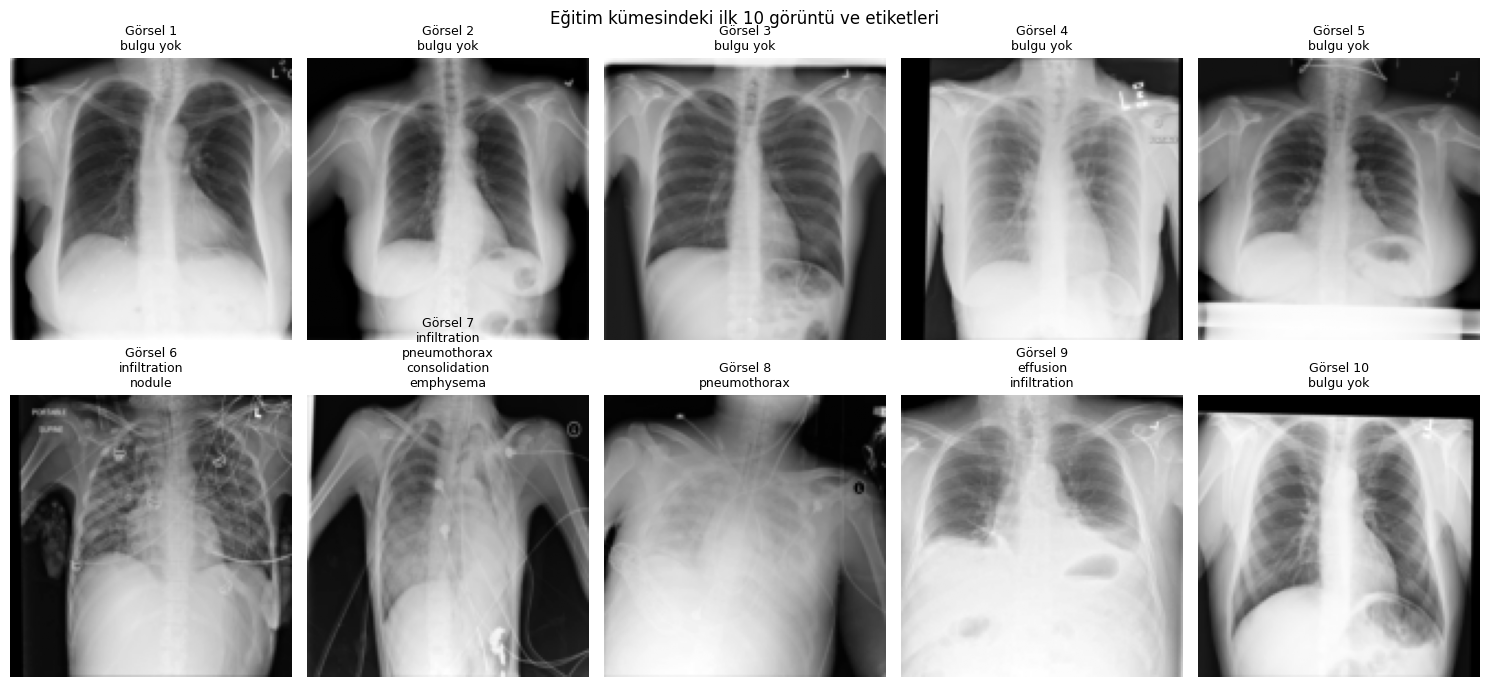

In [19]:
def etiket_metni(etiket):
    adlar = [LABELS[i] for i in np.flatnonzero(etiket)]
    return "\n".join(adlar) if adlar else "bulgu yok"

train_images = data["train_images"]

fig, axes = plt.subplots(2, 5, figsize=(15, 7))
for i, ax in enumerate(axes.flat):
    ax.imshow(train_images[i], cmap="gray")
    ax.set_title(f"Görsel {i + 1}\n{etiket_metni(train_labels[i])}", fontsize=9)
    ax.axis("off")
plt.suptitle("Eğitim kümesindeki ilk 10 görüntü ve etiketleri")
plt.tight_layout()
plt.show()

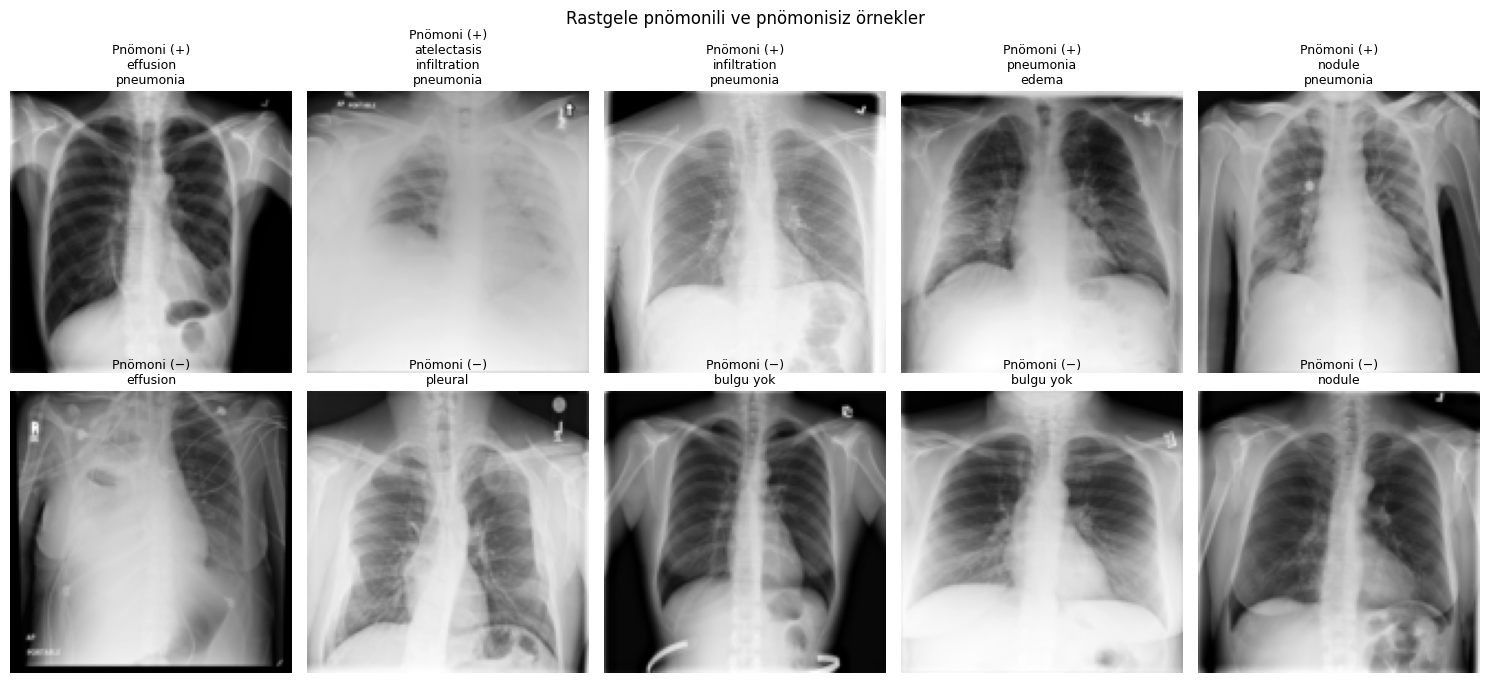

In [20]:
# Rastgele 5 pnömonili ve 5 pnömonisiz görüntü
pos_ornek = rng.choice(np.flatnonzero(y["train"] == 1), 5, replace=False)
neg_ornek = rng.choice(np.flatnonzero(y["train"] == 0), 5, replace=False)

fig, axes = plt.subplots(2, 5, figsize=(15, 7))
for satir, (indeksler, baslik) in enumerate([(pos_ornek, "Pnömoni (+)"), (neg_ornek, "Pnömoni (−)")]):
    for ax, i in zip(axes[satir], indeksler):
        ax.imshow(train_images[i], cmap="gray")
        ax.set_title(f"{baslik}\n{etiket_metni(train_labels[i])}", fontsize=9)
        ax.axis("off")
plt.suptitle("Rastgele pnömonili ve pnömonisiz örnekler")
plt.tight_layout()
plt.show()

## 7. Bulgular

*(Sayıları yukarıdaki çıktılara göre kontrol edip güncelleyin.)*

- **Boyut:** 112.120 görüntü; sabit eğitim / doğrulama / test bölmesi (yaklaşık %70 / %10 / %20). Görüntüler 128 × 128, tek kanal, `uint8` (0–255). Etiketler yalnızca 0 ve 1 değerini alıyor.
- **Ciddi sınıf dengesizliği:** Pnömoni pozitif oranı yaklaşık %1,3; her pozitif görüntüye kabaca 75–80 negatif düşüyor. Hep "negatif" diyen bir model bile ~%98,7 doğruluk alır. Bu nedenle model aşamasında doğruluk yerine **ROC-AUC ve PR-AUC** kullanılacak; dengesizlik yalnızca eğitim kümesinde ele alınacak, doğrulama ve test kümeleri gerçek dağılımlarıyla korunacak.
- **Eşlik eden bulgular:** Pnömonili görüntülerin çoğunda başka bulgular da (ör. infiltrasyon) etiketlenmiş. Bu bulgular radyolojik olarak benzer göründüğü için ayrım zor olacak.
- **Etiket gürültüsü:** Etiketler radyoloji raporlarından metin madenciliğiyle çıkarıldığı için bir kısmı hatalı olabilir.
- **Veri sızıntısı:** Resmî NIH bölmesi hasta düzeyinde yapıldığından aynı hasta farklı kümelerde yer almaz; bölme olduğu gibi kullanılacak.

## 8. Ortam bilgisi

In [21]:
import sys, matplotlib, medmnist
print("Python    :", sys.version.split()[0])
for m in [np, pd, matplotlib, medmnist]:
    print(f"{m.__name__:<10}:", m.__version__)

Python    : 3.13.18
numpy     : 2.4.6
pandas    : 2.2.3
matplotlib: 3.10.0
medmnist  : 3.0.2
